# Window Experiment

**Purpose.** Choose the `window_chars` and `overlap_chars` that the encoder trains on. The temporary fixed-window chunker (`chunk_contract`) has no default size, and the choice matters: a chunk longer than the model's 512-token limit is truncated, so its tail is dropped while its labels are kept (label noise), whereas a chunk that is too small splits clauses apart.

On the 408 official training contracts only (never `test.json`), this notebook measures the truncation rate, compute cost, clause coverage and per-category positive counts for several candidate windows. Then, it picks the values for `configs/encoder.yaml`. The results are specific to the fixed-window stub and should be revisited when the boundary aware chunker replaces it.

## Setup & Imports
Makes the repo's `src` package importable from `notebooks/` and loads the project and plotting tools.

In [1]:
import sys
sys.path.insert(0, "..")

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

from src.chunking.chunker import chunk_contract
from src.labels.loader import load_cuad
from src.labels.splits import split_by_contract
from src.labels.categories import CATEGORIES
from src.models.encoder.config import load_config
from src.models.encoder.dataset import build_labeled_chunks
from src.models.encoder.loss import compute_pos_weight

C:\Users\User\Desktop\Accenture 1R Project\Accenture-1R-contract-review-challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load & Split the Data
Loads the 408 training contracts and applies the same seeded, grouped-by-contract split the training script will use. Only the train contracts are used for chunk statistics; `test.json` is never touched.

In [2]:
config = load_config("../configs/encoder.yaml")
contracts = load_cuad("../data/cuad/train_separate_questions.json")

train, val = split_by_contract(contracts, val_fraction=config.val_fraction, seed=config.seed)

print(f"train={len(train)}  val={len(val)}  total={len(train) + len(val)}")

train=326  val=82  total=408


## Build Chunks For Each Candidate
Chunks and labels the train contracts with the existing `build_labeled_chunks` for each candidate window, with overlap set to 12% of the window. The candidates run from 600 to 2000 characters because the first pass (1000-2500) showed truncation above the 1% target even at 1000.

In [3]:
windows = [600, 800, 1000, 1500, 2000]
overlaps = {window: round(0.12 * window) for window in windows}

chunk_maps = {}
for window in windows:
    chunk_maps[window] = build_labeled_chunks(train, window, overlaps[window])
    print(f"window={window}  overlap={overlaps[window]}  chunks={len(chunk_maps[window])}")

window=600  overlap=72  chunks=34882


window=800  overlap=96  chunks=26182


window=1000  overlap=120  chunks=20973


window=1500  overlap=180  chunks=14018


window=2000  overlap=240  chunks=10547


## Truncation Rate (Core Decision)
Tokenizes a seeded sample of 2,000 chunks per window without truncation and reports how many exceed the 512-token limit. Token counts include the two special tokens, so a chunk is truncated when its length is over 512 (the red line). The goal is under 1%.

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (538 > 512). Running this sequence through the model will result in indexing errors


window=600  truncated=0.1%  p50=133  p95=245  p99=339  max=538  chars/token=4.01
window=800  truncated=0.7%  p50=178  p95=324  p99=461  max=742  chars/token=4.00


window=1000  truncated=1.7%  p50=221  p95=396  p99=568  max=956  chars/token=4.02


window=1500  truncated=8.8%  p50=329  p95=579  p99=830  max=1393  chars/token=4.04


window=2000  truncated=24.2%  p50=441  p95=791  p99=1148  max=1697  chars/token=4.00


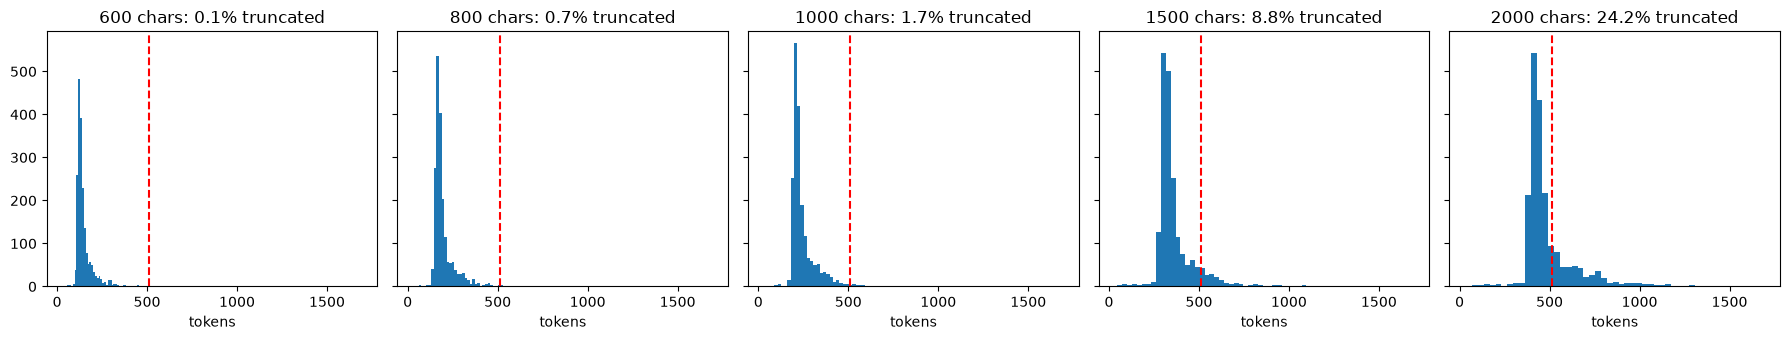

In [4]:
tokenizer = AutoTokenizer.from_pretrained(config.model_name)
sample_size, limit = 2000, config.max_length
token_lengths = {}
rows = []

for window in windows:
    # Seeded random sample of chunks, so the result is reproducible per window
    rng = random.Random(config.seed)
    sampled = rng.sample(chunk_maps[window], min(sample_size, len(chunk_maps[window])))
    texts = [lc.chunk.text for lc in sampled]

    # Token counts without truncation (special tokens included, so truncated means > limit)
    encodings = tokenizer(texts, truncation=False)
    lengths = np.array([len(ids) for ids in encodings["input_ids"]])

    # Truncation rate, percentiles and max
    truncation_rate = (lengths > limit).mean()
    p50, p95, p99 = np.percentile(lengths, [50, 95, 99])
    chars_per_token = sum(len(t) for t in texts) / lengths.sum()
    print(f"window={window}  truncated={truncation_rate:.1%}  "
          f"p50={p50:.0f}  p95={p95:.0f}  p99={p99:.0f}  max={lengths.max()}  "
          f"chars/token={chars_per_token:.2f}")

    # Keep the lengths for the histograms and a summary row for the decision table
    token_lengths[window] = lengths
    rows.append({"window": window, "truncation_rate": truncation_rate,
                 "p95": p95, "p99": p99, "max": lengths.max(),
                 "mean_tokens": np.minimum(lengths, limit).mean()})

# One histogram per window on shared axes, with the model limit marked in red
fig, axes = plt.subplots(1, len(windows), figsize=(18, 3.5), sharex=True, sharey=True)
for ax, window in zip(axes, windows):
    ax.hist(token_lengths[window], bins=50)
    ax.axvline(limit, color="red", linestyle="--")
    ax.set_title(f"{window} chars: {(token_lengths[window] > limit).mean():.1%} truncated")
    ax.set_xlabel("tokens")
plt.tight_layout()
plt.show()

## Chunk Count & Compute Cost
Estimates the tokens processed per epoch as chunk count x mean tokens per chunk (capped at 512), relative to the cheapest window. It is a rough guide to training time; smaller windows mean more, shorter chunks.

In [5]:
cost = pd.DataFrame(rows).set_index("window")
cost["overlap"] = pd.Series(overlaps)
cost["train_chunks"] = pd.Series({w: len(chunk_maps[w]) for w in windows})
cost["tokens_per_epoch_m"] = cost["train_chunks"] * cost["mean_tokens"] / 1e6
cost["relative_cost"] = cost["tokens_per_epoch_m"] / cost["tokens_per_epoch_m"].min()
cost[["overlap", "train_chunks", "mean_tokens", "tokens_per_epoch_m", "relative_cost"]].round(2)

,overlap,train_chunks,mean_tokens,tokens_per_epoch_m,relative_cost
window,,,,,
600,72,34882,148.73,5.19,1.10
800,96,26182,198.07,5.19,1.10
1000,120,20973,245.11,5.14,1.09
1500,180,14018,353.03,4.95,1.05
2000,240,10547,445.78,4.70,1.00


## Clause Span Lengths
Measures how long the annotated clauses are, in characters. A span longer than the window can never fit inside one chunk, so these lengths bound what any window can contain whole.

In [6]:
span_lengths = np.array([s.end - s.start for c in train for s in c.spans])
print(f"{len(span_lengths)} annotated spans in {len(train)} train contracts\n")

# Span length percentiles, and the share of spans longer than each candidate window
quantiles = [50, 75, 90, 95, 99, 100]
print(pd.Series(np.percentile(span_lengths, quantiles), index=[f"p{q}" for q in quantiles]).round(0).to_string())
print()
print(pd.Series({w: f"{(span_lengths > w).mean():.1%}" for w in windows}, name="spans longer than window").to_string())

# Categories with the longest typical clauses
by_category = pd.DataFrame([(s.category, s.end - s.start) for c in train for s in c.spans],
                           columns=["category", "chars"])
print()
print(by_category.groupby("category")["chars"].median().sort_values(ascending=False).head(8).to_string())

9175 annotated spans in 326 train contracts

p50      202.0
p75      375.0
p90      604.0
p95      775.0
p99     1387.0
p100    3884.0

600     10.2%
800      4.5%
1000     2.8%
1500     0.7%
2000     0.3%

category
Affiliate License-Licensee           528.0
Affiliate License-Licensor           484.0
Irrevocable Or Perpetual License     484.0
Uncapped Liability                   425.0
Most Favored Nation                  398.5
Unlimited/All-You-Can-Eat-License    385.5
Post-Termination Services            382.0
Competitive Restriction Exception    375.0


## Clause Coverage by Window
Measures the share of annotated spans that lie entirely inside at least one chunk. A span cut by a chunk boundary is still labeled positive, but the model never sees it whole. Overlap is 12% of the window.

In [7]:
def bounds_by_contract(chunks) -> dict:
    """Group chunk (start, end) offsets by contract id as numpy arrays."""
    grouped = {}
    for chunk in chunks:
        grouped.setdefault(chunk.contract_id, []).append((chunk.start, chunk.end))
    return {contract_id: np.array(pairs) for contract_id, pairs in grouped.items()}


def span_coverage(contracts, bounds) -> float:
    """Return the share of spans that lie entirely inside at least one chunk."""
    contained = total = 0
    for contract in contracts:
        total += len(contract.spans)
        if contract.contract_id not in bounds:
            continue
        starts, ends = bounds[contract.contract_id].T
        for span in contract.spans:
            contained += bool(((starts <= span.start) & (ends >= span.end)).any())
    return contained / total


coverage = {w: span_coverage(train, bounds_by_contract([lc.chunk for lc in chunk_maps[w]])) for w in windows}
print(pd.Series({w: f"{c:.1%}" for w, c in coverage.items()}, name="spans fully inside a chunk").to_string())

600     66.0%
800     75.1%
1000    80.3%
1500    90.1%
2000    93.5%


## Choose the Window
Combines truncation, coverage and cost in one table. The rule is the largest window whose truncation rate is under 1%; coverage and cost are checked afterwards as a cost of that choice.

In [8]:
summary = cost[["overlap", "train_chunks", "truncation_rate", "p99", "relative_cost"]].copy()
summary["coverage"] = pd.Series(coverage)

passing = summary.index[summary["truncation_rate"] < 0.01]
chosen_window = int(passing.max()) if len(passing) else int(summary.index.min())

print(summary.round(3).to_string())
print(f"\nWindows under 1% truncation: {list(passing)}")
print(f"Chosen window: {chosen_window}")

        overlap  train_chunks  truncation_rate      p99  relative_cost  coverage
window                                                                          
600          72         34882            0.000   339.01          1.103     0.660
800          96         26182            0.007   461.03          1.103     0.751
1000        120         20973            0.017   568.05          1.093     0.803
1500        180         14018            0.088   830.04          1.053     0.901
2000        240         10547            0.242  1148.03          1.000     0.935

Windows under 1% truncation: [600, 800]
Chosen window: 800


## Overlap Sweep
At the chosen window, rebuilds the chunks with several overlap fractions and measures chunk count and span coverage. The rule is the smallest overlap whose coverage is within one percentage point of the best swept.

          overlap  chunks  coverage
fraction                           
0.00            0   23102     0.689
0.05           40   24293     0.711
0.10           80   25618     0.740
0.15          120   27093     0.765
0.25          200   30637     0.812

Chosen overlap: 200 chars (25% of the window)


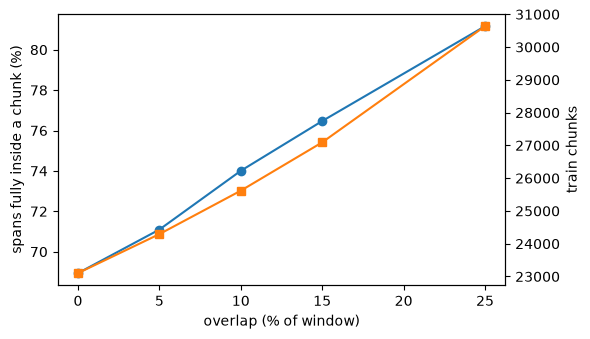

In [9]:
fractions = [0.0, 0.05, 0.10, 0.15, 0.25]
sweep_rows = []
for fraction in fractions:
    overlap = round(fraction * chosen_window)
    chunks = [ch for c in train for ch in chunk_contract(c.contract_id, c.text, chosen_window, overlap)]
    sweep_rows.append({"fraction": fraction, "overlap": overlap, "chunks": len(chunks),
                       "coverage": span_coverage(train, bounds_by_contract(chunks))})
sweep = pd.DataFrame(sweep_rows).set_index("fraction")

# Smallest overlap fraction within one point of the best coverage
best = sweep["coverage"].max()
chosen_fraction = sweep.index[sweep["coverage"] >= best - 0.01].min()
chosen_overlap = int(sweep.loc[chosen_fraction, "overlap"])

print(sweep.round(3).to_string())
print(f"\nChosen overlap: {chosen_overlap} chars ({chosen_fraction:.0%} of the window)")

# Coverage against chunk count as overlap grows
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sweep.index * 100, sweep["coverage"] * 100, marker="o")
ax.set_xlabel("overlap (% of window)")
ax.set_ylabel("spans fully inside a chunk (%)")
ax2 = ax.twinx()
ax2.plot(sweep.index * 100, sweep["chunks"], marker="s", color="tab:orange")
ax2.set_ylabel("train chunks")
plt.tight_layout()
plt.show()

## Positives per Category
Builds train and validation chunks at the chosen window and overlap, and counts positive chunks for each of the 41 categories. Shows the raw `neg / pos` weight next to the capped `pos_weight`, and flags categories that are too rare in validation for reliable thresholds.

In [10]:
train_chunks = build_labeled_chunks(train, chosen_window, chosen_overlap)
val_chunks = build_labeled_chunks(val, chosen_window, chosen_overlap)
train_labels = np.array([lc.labels for lc in train_chunks])
val_labels = np.array([lc.labels for lc in val_chunks])

# Raw neg/pos weight versus the capped weight the loss will actually use
pos = train_labels.sum(axis=0)
raw_weight = np.divide(len(train_labels) - pos, pos, out=np.ones(len(pos)), where=pos > 0)
pos_weight = compute_pos_weight(train_labels, config.pos_weight_cap).numpy()

positives = pd.DataFrame({
    "category": CATEGORIES,
    "train_pos": pos,
    "val_pos": val_labels.sum(axis=0),
    "train_rate": train_labels.mean(axis=0).round(4),
    "raw_weight": raw_weight.round(1),
    "pos_weight": pos_weight.round(1),
}).sort_values("train_pos").reset_index(drop=True)

print(f"train chunks={len(train_labels)}  val chunks={len(val_labels)}")
print(f"chunks with no label: train={(train_labels.sum(axis=1) == 0).mean():.1%}  "
      f"val={(val_labels.sum(axis=1) == 0).mean():.1%}")
print(f"categories with 0 val positives: {(positives['val_pos'] == 0).sum()}   "
      f"with < 5: {(positives['val_pos'] < 5).sum()}")
print(f"categories hitting the pos_weight cap ({config.pos_weight_cap:g}): {(positives['raw_weight'] > config.pos_weight_cap).sum()}")
positives

train chunks=30637  val chunks=6141
chunks with no label: train=73.2%  val=72.6%
categories with 0 val positives: 0   with < 5: 1
categories hitting the pos_weight cap (50): 37


,category,train_pos,val_pos,train_rate,raw_weight,pos_weight
0,Unlimited/All-You-Can-Eat-License,27,17,0.0009,1133.7,50.000000
1,Third Party Beneficiary,34,14,0.0011,900.1,50.000000
2,Price Restrictions,43,6,0.0014,711.5,50.000000
3,Most Favored Nation,51,13,0.0017,599.7,50.000000
4,No-Solicit Of Customers,59,14,0.0019,518.3,50.000000
5,Source Code Escrow,62,17,0.0020,493.1,50.000000
6,Non-Disparagement,88,2,0.0029,347.1,50.000000
7,Affiliate License-Licensor,90,10,0.0029,339.4,50.000000
8,No-Solicit Of Employees,102,25,0.0033,299.4,50.000000
9,Joint Ip Ownership,126,23,0.0041,242.2,50.000000


## Chosen Configuration
Prints the values to copy into `configs/encoder.yaml`, next to the placeholders currently in the file.

In [11]:
print("Current configs/encoder.yaml:")
print(f"  window_chars: {config.window_chars}\n  overlap_chars: {config.overlap_chars}")
print("\nChosen by this experiment:")
print(f"  window_chars: {chosen_window}\n  overlap_chars: {chosen_overlap}")

Current configs/encoder.yaml:
  window_chars: 1500
  overlap_chars: 200

Chosen by this experiment:
  window_chars: 800
  overlap_chars: 200


## Analysis & Conclusion

**Findings** (train contracts only; 326 train / 82 val after the grouped split)
- **Truncation is the binding constraint.** Text averages about 4.0 characters per token, but the tail is heavy: truncation is 0.1% at 600 characters, 0.7% at 800, 1.7% at 1000, 8.8% at 1500 and 24.2% at 2000. The 1500-character placeholder in the YAML would have dropped the tail of about 1 in 11 chunks. Each estimate carries about +/-0.2 points (2,000-chunk sample).
- **Window size is not a compute lever.** Tokens per epoch stay within about 10% across all windows (4.7M to 5.2M). Smaller windows mean more but shorter chunks, so training cost does not argue against 800.
- **Smaller windows cut clauses apart.** Median clause length is 202 characters, but p95 is 775 and p99 is 1,387. At 12% overlap, the share of clauses lying whole inside one chunk is 66% at 600, 75% at 800, 80% at 1000 and 90% at 1500. Choosing 800 over 1500 trades about 15 points of whole clause coverage for a truncation rate under 1%.
- **Overlap helps but never plateaus.** At 800 characters, coverage rises roughly linearly from 69% (no overlap) to 81% (25% overlap), while chunks rise 33% (23,102 to 30,637). The 200-character overlap is about the median clause length. No overlap fixes the long clauses, since 4.5% of spans are longer than 800 characters and can never fit.
- **Labels are very sparse.** 73% of chunks carry no label. The rarest category (Unlimited/All-You-Can-Eat-License) has 27 train chunks (0.09%), and Non-Disparagement has only 2 val positives, so its threshold will be unreliable. No category has zero val positives.
- **The `pos_weight_cap` of 50 binds for 37 of 41 categories** (raw weights reach about 1,134), so those categories all get the same weight of 50 and the rarity ordering is lost.

**Decision.** `window_chars: 800` (largest window under 1% truncation) and `overlap_chars: 200` (the largest overlap swept; coverage had not plateaued), replacing the placeholders of 1500 and 200.

**Caveats and next steps**
- The 1% rule is a heuristic, not validated. If error analysis shows weak recall on long clause categories (License Grant, the Affiliate License categories, Irrevocable Or Perpetual License), try 1000 with 150 overlap.
- Truncation only hurts labels when the dropped tail contains the labeled span; the true label noise rate is below the truncation rate, but this notebook does not measure it.
- Coverage counts whole-clause containment; a clause cut by a boundary is still labeled positive in each chunk it touches.
- Treat these values as interim. They are specific to the fixed-window stub, and a boundary aware chunker sized in tokens should replace the overlap workaround. Re-run the truncation check and retrain when it lands.
- Revisit `pos_weight_cap` (for example 100, or a square root weighting) since the current cap flattens 37 categories to one weight.
- Log `window_chars` and `overlap_chars` with the model in MLflow, so inference chunks the same way as training.